In [6]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511039/notebook
!ls ..

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/simuteh-2330511039/notebook
data  hasil  laporan  notebook	requirements.txt  src


In [12]:
# KODE 1.1

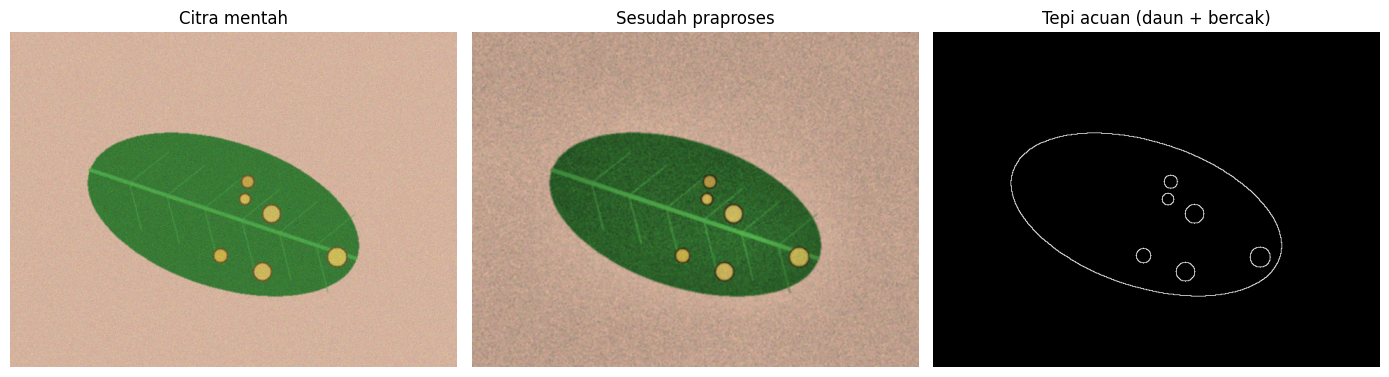

In [11]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

In [ ]:
# KODE 1.2

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 544.0


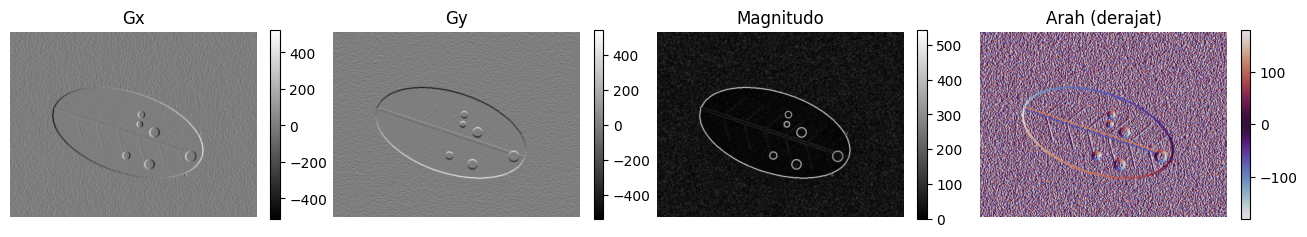

In [13]:
g = pra[:, :, 2].astype(np.float32)                   # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)                  # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)                  # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)

In [ ]:
# KODE 1.3

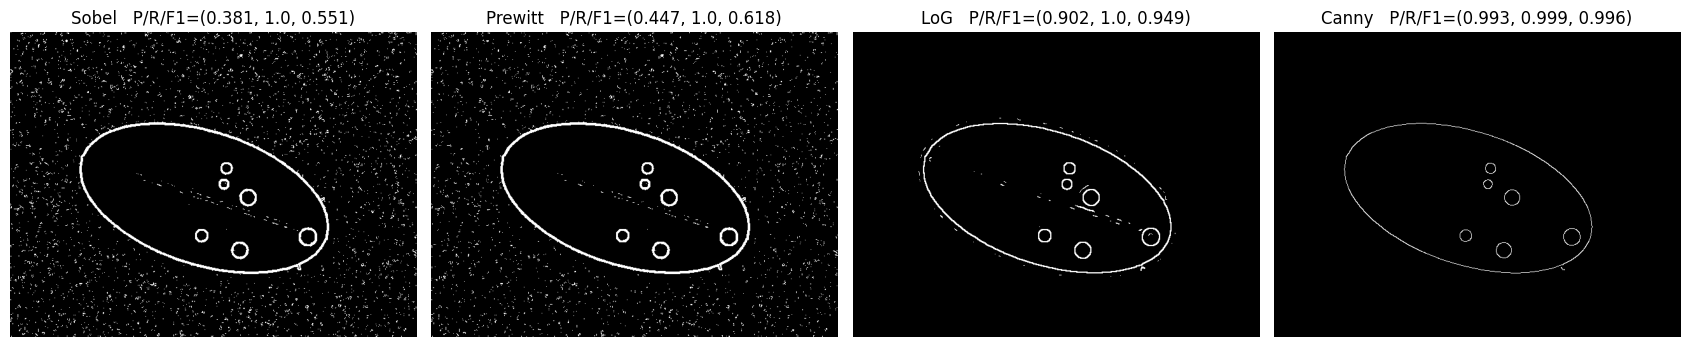

In [14]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma),
                      cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) *
            255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log,
          "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}   P/R/F1={skor_tepi(e, acuan)}" for nm, e
       in hasil.items()],
       ukuran=(17, 3.6))

In [ ]:
# KODE 1.4

In [16]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R",
                          im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal",
                                          "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R",
                                                             "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)


                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.772  0.762  0.766
                LoG      0.578  0.999  0.718
                Prewitt  0.789  0.975  0.866
                Sobel    0.746  0.978  0.838
          R     Canny    0.988  0.979  0.982
                LoG      0.820  0.999  0.879
                Prewitt  0.503  0.998  0.621
                Sobel    0.437  0.998  0.556
praproses Gray  Canny    0.726  0.952  0.816
                LoG      0.491  0.998  0.633
                Prewitt  0.560  0.998  0.709
                Sobel    0.522  0.998  0.674
          R     Canny    0.961  0.990  0.973
                LoG      0.735  0.999  0.813
                Prewitt  0.450  0.998  0.593
                Sobel    0.398  0.998  0.541


In [ ]:
# KODE 1.5

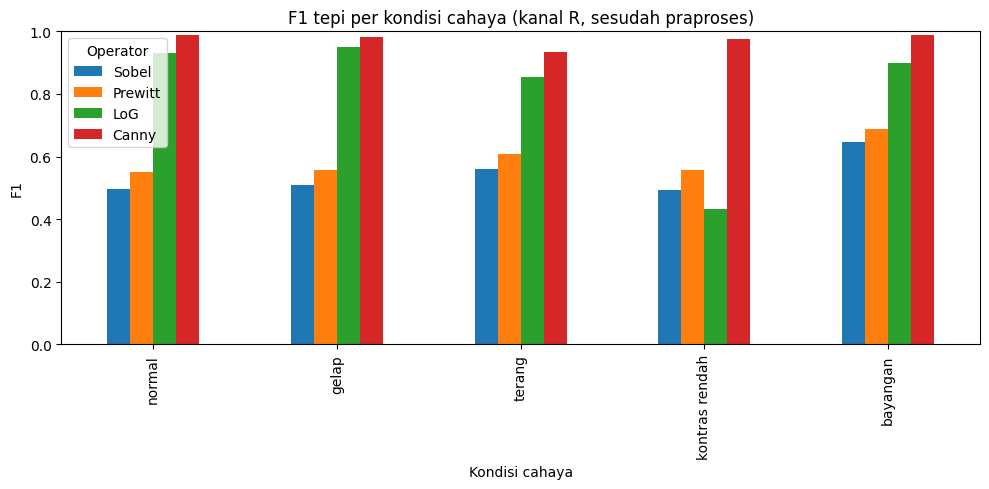

metode          Sobel  Prewitt    LoG  Canny
kondisi                                     
normal          0.497    0.552  0.930  0.987
gelap           0.508    0.556  0.951  0.981
terang          0.561    0.609  0.855  0.935
kontras rendah  0.494    0.558  0.432  0.976
bayangan        0.645    0.689  0.899  0.988


In [17]:
pil = tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
pivot = pil.groupby(["kondisi", "metode"])["F1"].mean().unstack()
pivot = pivot[["Sobel", "Prewitt", "LoG", "Canny"]]
urutan = [k for k in tabel_tepi.kondisi.unique() if k in pivot.index]
pivot = pivot.reindex(urutan)
pivot.index = pivot.index.str.replace("_", " ")

ax = pivot.plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
ax.set_title("F1 tepi per kondisi cahaya (kanal R, sesudah praproses)")
ax.set_xlabel("Kondisi cahaya")
ax.set_ylabel("F1")
ax.legend(title="Operator")
plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150)
plt.show()
print(pivot.round(3))

In [ ]:
# KODE 2.1

In [18]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]          # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1",
                                     "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1",
                                          "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas",
                        values="R_bercak").round(3))

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.522  0.995  0.640     0.980
      30/90    0.019  0.998  0.038     0.989
      50/150   0.089  0.996  0.146     0.983
1.0   100/200  0.978  0.993  0.986     0.968
      30/90    0.209  0.995  0.303     0.979
      50/150   0.897  0.994  0.938     0.974
2.0   100/200  0.818  0.807  0.812     0.730
      30/90    0.961  0.990  0.973     0.948
      50/150   0.985  0.977  0.981     0.868
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.979   0.980
      30/90    0.993   0.985
      50/150   0.985   0.981
1.0   100/200  0.974   0.962
      30/90    0.978   0.979
      50/150   0.976   0.973
2.0   100/200  0.760   0.701
      30/90    0.953   0.943
      50/150   0.900   0.836


In [ ]:
# KODE 2.2

In [19]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x
median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R",
                     pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis",
                      skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90",
                      skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1",
                                    "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi",
                       values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.546  0.627           0.760   0.781   0.873
      tetap 30/90     0.763  0.830           0.922   0.760   0.802
R     otomatis        0.476  0.569           0.636   0.852   0.920
      tetap 30/90     0.988  0.981           0.976   0.987   0.935
kanal  kondisi       
Gray   bayangan          123.8
       gelap             137.6
       kontras_rendah    149.6
       normal            169.0
       terang            194.4
R      bayangan          126.6
       gelap             148.0
       kontras_rendah    150.9
       normal            182.8
       terang            197.9
Name: median, dtype: float64


In [ ]:
# KODE 2.4

In [22]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra = praproses(img, PARAM)

    for kanal, g in [("Gray", cv2.cvtColor(pra, cv2.COLOR_BGR2GRAY)), ("R", pra[:, :, 2])]:
        # Hitung F1 untuk ambang median (Kode 2.2)
        _, _, f1_median = skor_tepi(canny_otomatis(g), ac)

        # Hitung F1 untuk canny_persentil q=90, 95, 98
        f1_q90 = skor_tepi(canny_persentil(g, q=90, rasio=0.4, sigma=2.0), ac)[2]
        f1_q95 = skor_tepi(canny_persentil(g, q=95, rasio=0.4, sigma=2.0), ac)[2]
        f1_q98 = skor_tepi(canny_persentil(g, q=98, rasio=0.4, sigma=2.0), ac)[2]

        baris.append([d.kondisi_cahaya, kanal, f1_q90, f1_q95, f1_q98, f1_median])

df_persentil = pd.DataFrame(baris, columns=["kondisi", "kanal", "q=90", "q=95", "q=98", "ambang_median"])
tabel_10 = df_persentil.groupby(["kondisi", "kanal"]).mean().round(3)
print(tabel_10)

                       q=90   q=95   q=98  ambang_median
kondisi        kanal                                    
bayangan       Gray   0.064  0.223  0.759          0.546
               R      0.068  0.160  0.988          0.476
gelap          Gray   0.065  0.272  0.783          0.627
               R      0.067  0.119  0.983          0.569
kontras_rendah Gray   0.052  0.089  0.729          0.760
               R      0.055  0.083  0.895          0.636
normal         Gray   0.062  0.308  0.767          0.781
               R      0.062  0.164  0.990          0.852
terang         Gray   0.059  0.265  0.785          0.873
               R      0.063  0.269  0.896          0.920


In [ ]:
# KODE 2.3

kanal            Gray      R
kondisi                     
bayangan        811.8    0.0
gelap           864.0    0.0
kontras_rendah  107.0    0.0
normal          971.2    0.0
terang          793.8  199.5


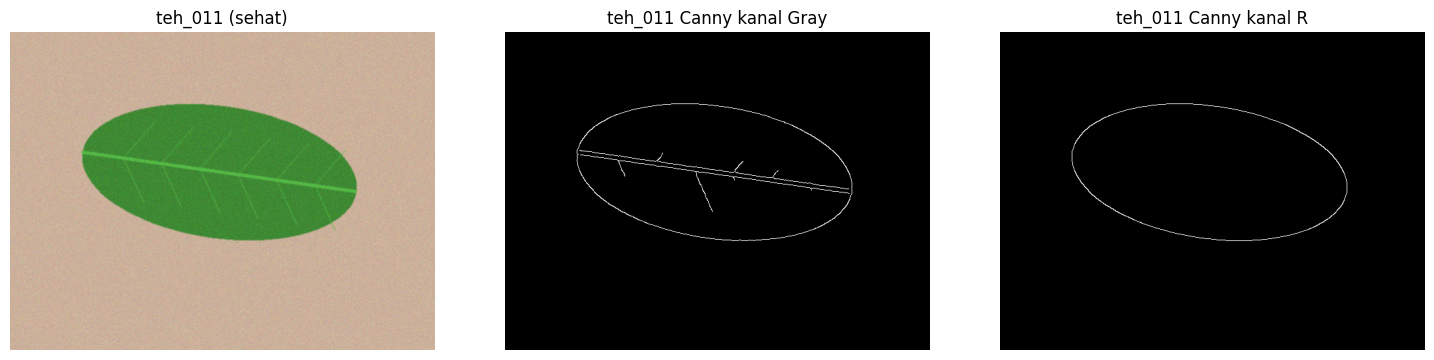

In [23]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0           # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R",
                     pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal",
                                     "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal",
                        values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul,
       ukuran=(15, 3.6))